# 05 授業の9節点熱回路

2026_環境工学特論Ⅰの4種類の壁・48時間外気条件を保持してvtsimnxへ書き換えた。

## 到達目標
各壁の容量を両側へ1/2ずつ配分。室内対流4.4、放射4.6、室外側17.9+4.6 W/(m²K)。独立行列式と全48ステップを照合済。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/05/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "05"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'05_classroom': {'builder': {},
                  'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                           'end': '2026-01-02T23:00:00',
                                           'length': 48,
                                           'timestep': 3600}},
                  'nodes': [{'key': 'outside',
                             't': [10.0,
                                   11.294095225512603,
                                   12.5,
                                   13.535533905932738,
                                   14.330127018922193,
                                   14.82962913144534,
                                   15.0,
                                   14.82962913144534,
                                   14.330127018922195,
                                   13.535533905932738,
                                   12.5,
                                   11.294095225512605,
                                   10.0,
                                   8.705904774487395,
                                   7.500000000000002,
                                   6.464466094067264,
                                   5.669872981077807,
                                   5.1703708685546585,
                                   5.0,
                                   5.170370868554658,
                                   5.669872981077807,
                                   6.464466094067261,
                                   7.499999999999998,
                                   8.705904774487392,
                                   9.999999999999998,
                                   11.294095225512606,
                                   12.5,
                                   13.535533905932738,
                                   14.330127018922191,
                                   14.82962913144534,
                                   15.0,
                                   14.829629131445342,
                                   14.330127018922195,
                                   13.535533905932736,
                                   12.5,
                                   11.294095225512605,
                                   10.000000000000002,
                                   8.705904774487399,
                                   7.5000000000000036,
                                   6.464466094067268,
                                   5.669872981077806,
                                   5.170370868554661,
                                   5.0,
                                   5.170370868554658,
                                   5.669872981077805,
                                   6.464466094067264,
                                   7.499999999999993,
                                   8.705904774487395]},
                            {'key': 'theta_i', 't': 20, 'calc_t': True},
                            {'key': 'theta_1i', 't': 20, 'calc_t': True, 'thermal_mass': 5688780.0},
                            {'key': 'theta_1o', 't': 20, 'calc_t': True, 'thermal_mass': 5688780.0},
                            {'key': 'theta_2i', 't': 20, 'calc_t': True, 'thermal_mass': 53580.8},
                            {'key': 'theta_2o', 't': 20, 'calc_t': True, 'thermal_mass': 53580.8},
                            {'key': 'theta_3i', 't': 20, 'calc_t': True, 'thermal_mass': 114830.40000000001},
                            {'key': 'theta_3o', 't': 20, 'calc_t': True, 'thermal_mass': 114830.40000000001},
                            {'key': 'theta_4i', 't': 20, 'calc_t': True, 'thermal_mass': 343586.88},
                            {'key': 'theta_4o', 't': 20, 'calc_t': True, 'thermal_mass': 343586.88}],
                  'ventilation_branches': [],
                  'thermal_branches': [{'key': 'theta_i->theta_1i',
                                        'source': 'theta_i',
                                        'target': 'theta_1i',
                                        'conductance': 176.0},
                                       {'key': 'theta_1i->theta_1o',
                                        'source': 'theta_1i',
                                        'target': 'theta_1o',
                                        'conductance': 426.6666666666667},
                                       {'key': 'theta_1o->outside',
                                        'source': 'theta_1o',
                                        'target': 'outside',
                                        'conductance': 900.0},
                                       {'key': 'theta_i->theta_2i',
                                        'source': 'theta_i',
                                        'target': 'theta_2i',
                                        'conductance': 176.0},
                                       {'key': 'theta_2i->theta_2o',
                                        'source': 'theta_2i',
                                        'target': 'theta_2o',
                                        'conductance': 14.399999999999999},
                                       {'key': 'theta_2o->outside',
                                        'source': 'theta_2o',
                                        'target': 'outside',
                                        'conductance': 900.0},
                                       {'key': 'theta_i->theta_3i',
                                        'source': 'theta_i',
                                        'target': 'theta_3i',
                                        'conductance': 176.0},
                                       {'key': 'theta_3i->theta_3o',
                                        'source': 'theta_3i',
                                        'target': 'theta_3o',
                                        'conductance': 13333.333333333334},
                                       {'key': 'theta_3o->outside',
                                        'source': 'theta_3o',
                                        'target': 'outside',
                                        'conductance': 900.0},
                                       {'key': 'theta_i->theta_4i',
                                        'source': 'theta_i',
                                        'target': 'theta_4i',
                                        'conductance': 176.0},
                                       {'key': 'theta_4i->theta_4o',
                                        'source': 'theta_4i',
                                        'target': 'theta_4o',
                                        'conductance': 266.6666666666667},
                                       {'key': 'theta_4o->outside',
                                        'source': 'theta_4o',
                                        'target': 'outside',
                                        'conductance': 900.0},
                                       {'key': 'theta_1i->theta_2i',
                                        'source': 'theta_1i',
                                        'target': 'theta_2i',
                                        'conductance': 46.0},
                                       {'key': 'theta_1i->theta_3i',
                                        'source': 'theta_1i',
                                        'target': 'theta_3i',
                                        'conductance': 46.0},
                                       {'key': 'theta_1i->theta_4i',
                                        'source': 'theta_1i',
                                        'target': 'theta_4i',
                                        'conductance': 46.0},
                                       {'key': 'theta_2i->theta_3i',
                                        'source': 'theta_2i',
                                        'target': 'theta_3i',
                                        'conductance': 46.0},
                                       {'key': 'theta_2i->theta_4i',
                                        'source': 'theta_2i',
                                        'target': 'theta_4i',
                                        'conductance': 46.0},
                                       {'key': 'theta_3i->theta_4i',
                                        'source': 'theta_3i',
                                        'target': 'theta_4i',
                                        'conductance': 46.0}]}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


05_classroom artifacts.1794699393823.output.f033c80cad7048669fb0790b9540d4fe


05_classroom


,outside,theta_1i,theta_1o,theta_2i,theta_2o,theta_3i,theta_3o,theta_4i,theta_4o,theta_i
time,,,,,,,,,,
2026-01-01 00:00:00,10.000000,18.646637,16.705257,15.021453,10.237973,11.915895,11.813096,14.443868,11.695132,15.006964
2026-01-01 01:00:00,11.294095,17.345409,15.123867,14.186549,11.322001,12.169381,12.113362,13.365114,11.762001,14.266613
2026-01-01 02:00:00,12.500000,16.365847,14.493787,14.215309,12.507713,12.991288,12.958329,13.566765,12.669585,14.284801
2026-01-01 03:00:00,13.535534,15.723301,14.377568,14.451317,13.533263,13.782459,13.765038,14.034108,13.575393,14.497796
2026-01-01 04:00:00,14.330127,15.355407,14.506405,14.719807,14.323402,14.421719,14.414472,14.490119,14.306858,14.746762


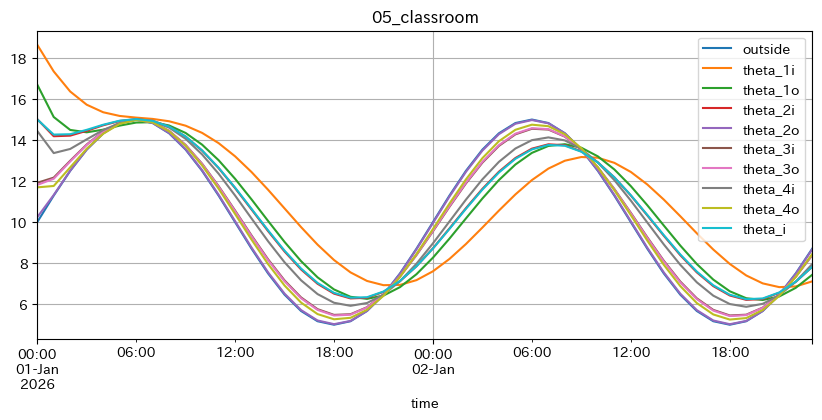

In [5]:
frames = {name: result.get_series_df('thermal_temperature', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_thermal_temperature.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


## 確認・発展
コンクリートの厚さを変えて熱遅れを調べる。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S011 parse_yaml_for_vtsimNX_r2.ipynb
- S012 parse_yaml_for_vtsimNX_r3.ipynb
- S263 vtsim_vs_simheat.ipynb
- S264 材料熱特性.ipynb
- S268 210925 浦和比較(井口)
- S269 Untitled5.ipynb のコピー
- S270 vtsim レターン温度制御(ホール分離） のコピー のコピー
- S271 床下温度計算_r1.ipynb
- S272 床下温度計算_r3.ipynb
- S273 床下温度計算_r4.ipynb
- S274 床下温度計算_r5.ipynb
- S275 床下温度計算_r5_簡易版.ipynb

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。